# Customer Churn & Retention Analytics

## Business Analytics Project

### Project Overview

This project analyzes customer churn for a telecommunications company using Python.

The analysis focuses on understanding why customers leave the company and identifying customer groups, services, and contract types that are associated with higher churn.

### Business Objectives

The main objectives of this analysis are:

- Understand the overall customer churn rate
- Identify customer segments with higher churn
- Analyze the relationship between services and customer churn
- Analyze how contract types affect customer retention
- Understand the impact of customer charges and tenure
- Generate data-driven insights that can help improve customer retention

### Target Variable

The target variable is **Churn**, which indicates whether a customer has left the company or remained with the company.

- **Yes** → Customer has left the company
- **No** → Customer has remained with the company

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("date/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape


(7043, 21)

## 2. Understanding the Dataset

Before cleaning and analyzing the data, we first examine the
structure of the dataset and understand the type of information
available for each customer.

The dataset contains information about:

- Customer demographics
- Services subscribed by customers
- Contract details
- Payment methods
- Monthly and total charges
- Customer churn status

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [9]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

## 3. Data Cleaning

Data cleaning is performed to ensure that the information is
accurate, consistent, and suitable for analysis.

During the initial inspection, the `TotalCharges` column was
identified as a data-quality issue because it was stored as text
instead of a numeric value.

We will convert this column into a numeric format and identify
any values that cannot be converted.

In [10]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [11]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [12]:
df[df["TotalCharges"].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [13]:
df = df.dropna(subset=["TotalCharges"])

In [14]:
df.shape

(7032, 21)

In [15]:

df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [16]:
df.dtypes


customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

## 3.1 Data Cleaning Summary

The dataset originally contained **7,043 customer records**.

During the data cleaning process:

- `TotalCharges` was converted from text to numeric format.
- 11 records contained missing or invalid total charge values.
- These 11 records were removed because a reliable total charge could not be determined.
- No duplicate records were found.
- No missing values remain in the cleaned dataset.

The final dataset contains **7,032 customers and 21 features** and is ready for exploratory analysis.

## 4. Overall Customer Churn

### Business Question

**How serious is customer churn for the company?**

Before investigating why customers leave, we first need to understand the overall churn situation.

This analysis will show:
- How many customers have left the company
- How many customers have stayed
- What percentage of the customer base has churned

This gives us a baseline for the company's overall customer retention performance.

In [17]:
churn_summary = df["Churn"].value_counts().to_frame("Customers")

churn_summary["Percentage"] = (
    churn_summary["Customers"] / len(df) * 100
).round(1)

churn_summary

,Customers,Percentage
Churn,,
No,5163,73.4
Yes,1869,26.6


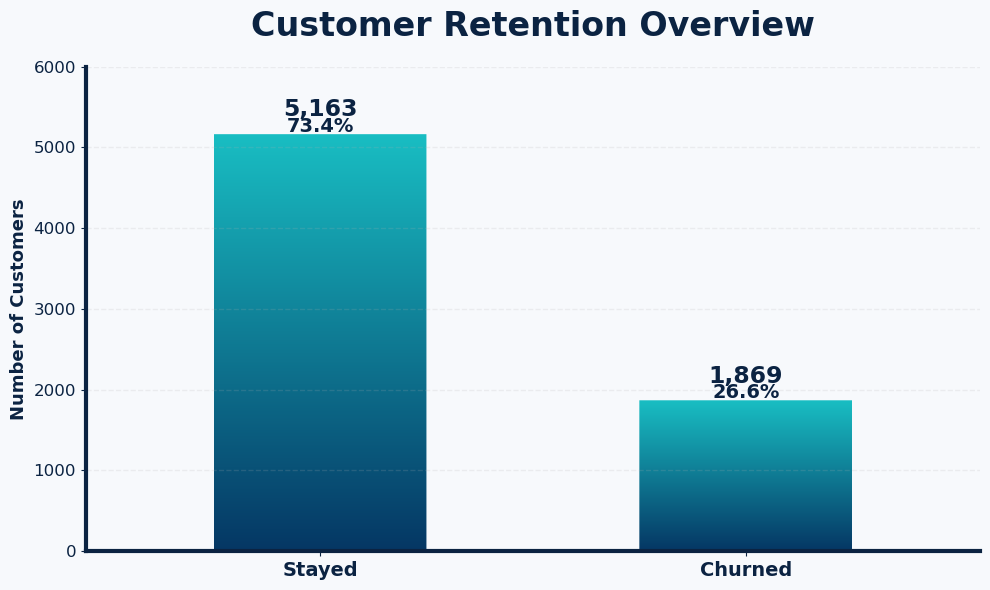

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Data
categories = ["Stayed", "Churned"]
values = churn_summary.loc[["No", "Yes"], "Customers"].values
percentages = churn_summary.loc[["No", "Yes"], "Percentage"].values

# Create figure
fig, ax = plt.subplots(figsize=(10, 6))

# Background
fig.patch.set_facecolor("#F7F9FC")
ax.set_facecolor("#F7F9FC")

x = np.arange(len(categories))
width = 0.50

# RGB colors in 0-1 range
bottom_color = np.array([5, 55, 100]) / 255
top_color = np.array([25, 190, 195]) / 255

for i, value in enumerate(values):

    # Rounded rectangle for clipping
    bar = FancyBboxPatch(
        (i - width / 2, 0),
        width,
        value,
        boxstyle="round,pad=0,rounding_size=0.08",
        linewidth=0,
        facecolor="none"
    )

    ax.add_patch(bar)

    # Create vertical gradient
    gradient = np.linspace(0, 1, 300).reshape(300, 1, 1)

    rgb = (
        bottom_color.reshape(1, 1, 3) * (1 - gradient)
        + top_color.reshape(1, 1, 3) * gradient
    )

    ax.imshow(
        rgb,
        extent=[
            i - width / 2,
            i + width / 2,
            0,
            value
        ],
        origin="lower",
        aspect="auto",
        interpolation="bicubic",
        transform=ax.transData,
        clip_path=bar,
        clip_on=True
    )

# Title
ax.set_title(
    "Customer Retention Overview",
    fontsize=24,
    fontweight="bold",
    color="#0B2342",
    pad=22
)

# Y-axis label
ax.set_ylabel(
    "Number of Customers",
    fontsize=13,
    fontweight="bold",
    color="#0B2342"
)

# X-axis
ax.set_xticks(x)
ax.set_xticklabels(
    categories,
    fontsize=14,
    fontweight="bold",
    color="#0B2342"
)

# Y-axis
ax.set_ylim(0, 6000)
ax.set_yticks(np.arange(0, 6001, 1000))

ax.tick_params(
    axis="y",
    labelsize=12,
    colors="#0B2342"
)

ax.tick_params(
    axis="x",
    colors="#0B2342"
)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=1,
    alpha=0.18
)

ax.set_axisbelow(True)

# Remove top/right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Dark left/bottom axes
ax.spines["left"].set_color("#0B2342")
ax.spines["left"].set_linewidth(3)

ax.spines["bottom"].set_color("#0B2342")
ax.spines["bottom"].set_linewidth(3)

# Labels above bars
for i, (value, percentage) in enumerate(zip(values, percentages)):

    ax.text(
        i,
        value + 220,
        f"{value:,}",
        ha="center",
        fontsize=17,
        fontweight="bold",
        color="#0B2342"
    )

    ax.text(
        i,
        value + 30,
        f"{percentage:.1f}%",
        ha="center",
        fontsize=14,
        fontweight="bold",
        color="#0B2342"
    )

ax.set_xlim(-0.55, 1.55)

plt.tight_layout()
plt.show()

### Business Insight

The analysis shows that **5,163 customers (73.4%) have stayed with the company**, while **1,869 customers (26.6%) have churned**.

This means that **more than one in every four customers has left the company**, indicating a significant customer retention challenge.

Although the majority of customers are still retained, the current churn level suggests that the company should investigate the factors contributing to customer loss, such as contract type, services used, pricing, and customer tenure.

### Business Takeaway

**Customer retention should be a key business priority.** Understanding which customer groups are more likely to churn can help the company design targeted retention strategies and reduce customer loss.

## 5. Customer Churn by Contract Type

### Business Question

**Business Question:** Is contract type associated with customer churn?

Customers may have different contract commitments, such as monthly, one-year, or two-year contracts.

This analysis compares churn across contract types to identify whether customers with shorter commitments are more likely to leave the company.

In [19]:
contract_churn = (
    df.groupby("Contract")["Churn"]
      .value_counts(normalize=True)
      .unstack(fill_value=0) * 100
)

contract_churn = contract_churn.round(1)

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.3,42.7
One year,88.7,11.3
Two year,97.2,2.8


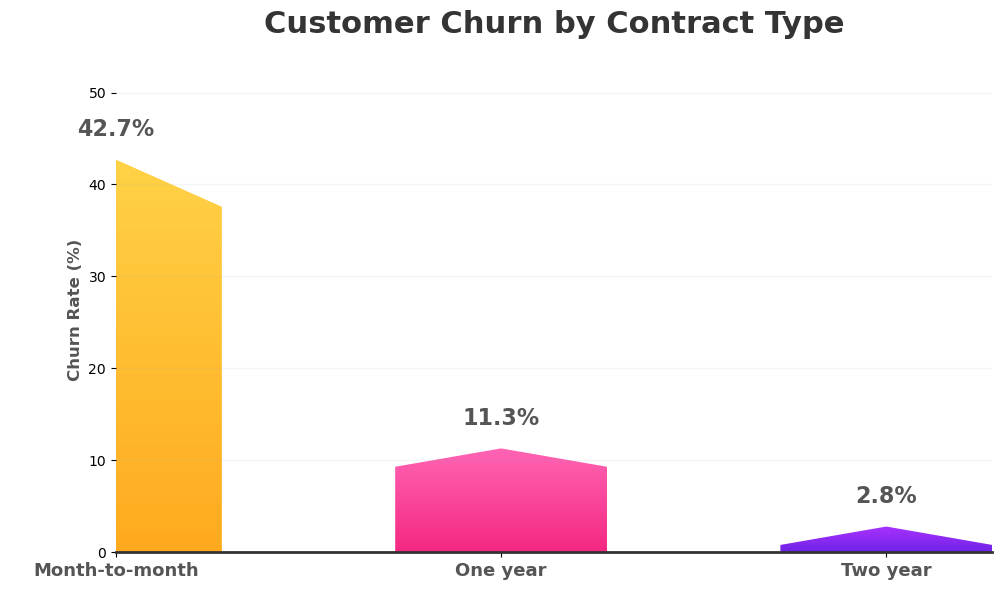

In [20]:
from matplotlib.patches import Polygon

# Churn rates
churn_rates = contract_churn["Yes"].sort_values(ascending=False)

categories = churn_rates.index
values = churn_rates.values

# Figure
fig, ax = plt.subplots(figsize=(10, 6))

fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

x = np.arange(len(categories))
width = 0.55

# Gradient colors for each bar
colors_bottom = [
    np.array([255, 170, 30]) / 255,
    np.array([245, 40, 130]) / 255,
    np.array([110, 35, 230]) / 255
]

colors_top = [
    np.array([255, 210, 70]) / 255,
    np.array([255, 100, 180]) / 255,
    np.array([170, 50, 255]) / 255
]

# Draw pointed / house-shaped bars
for i, value in enumerate(values):

    left = i - width / 2
    right = i + width / 2

    # Height of pointed roof
    roof_height = max(value * 0.12, 2)

    # Polygon points
    points = [
        (left, 0),
        (right, 0),
        (right, value - roof_height),
        (i, value),
        (left, value - roof_height)
    ]

    polygon = Polygon(
        points,
        closed=True,
        facecolor="none",
        edgecolor="none"
    )

    ax.add_patch(polygon)

    # Gradient
    gradient = np.linspace(0, 1, 400).reshape(400, 1, 1)

    rgb = (
        colors_bottom[i].reshape(1, 1, 3) * (1 - gradient)
        + colors_top[i].reshape(1, 1, 3) * gradient
    )

    ax.imshow(
        rgb,
        extent=[left, right, 0, value],
        origin="lower",
        aspect="auto",
        clip_path=polygon,
        clip_on=True
    )

# Title
ax.set_title(
    "Customer Churn by Contract Type",
    fontsize=22,
    fontweight="bold",
    color="#343434",
    pad=25
)

# Y-axis
ax.set_ylabel(
    "Churn Rate (%)",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

# X-axis
ax.set_xticks(x)
ax.set_xticklabels(
    categories,
    fontsize=13,
    fontweight="bold",
    color="#555555"
)

# Grid
ax.grid(
    axis="y",
    linestyle="-",
    linewidth=1,
    alpha=0.12
)

ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

# Bottom axis
ax.spines["bottom"].set_color("#333333")
ax.spines["bottom"].set_linewidth(2)

# Percentage labels
for i, value in enumerate(values):

    ax.text(
        i,
        value + 2,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight="bold",
        color="#555555"
    )

# Extra space above bars
ax.set_ylim(0, max(values) + 10)

plt.tight_layout()
plt.show()

## 6. Customer Churn by Tenure

### Business Question

**Are newer customers more likely to churn than long-term customers?**

Customer tenure represents how long a customer has been with the company.

By comparing churn across different tenure groups, we can identify whether customer retention is more challenging during the early stages of the customer relationship.

In [21]:
# Create customer tenure groups

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=[
        "0–12 Months",
        "13–24 Months",
        "25–48 Months",
        "49–72 Months"
    ],
    include_lowest=True
)

df["TenureGroup"].value_counts().sort_index()

TenureGroup
0–12 Months     2175
13–24 Months    1024
25–48 Months    1594
49–72 Months    2239
Name: count, dtype: int64

In [22]:
tenure_churn = (
    df.groupby("TenureGroup", observed=True)["Churn"]
      .value_counts(normalize=True)
      .unstack(fill_value=0) * 100
)

tenure_churn = tenure_churn.round(1)

tenure_churn

Churn,No,Yes
TenureGroup,,
0–12 Months,52.3,47.7
13–24 Months,71.3,28.7
25–48 Months,79.6,20.4
49–72 Months,90.5,9.5


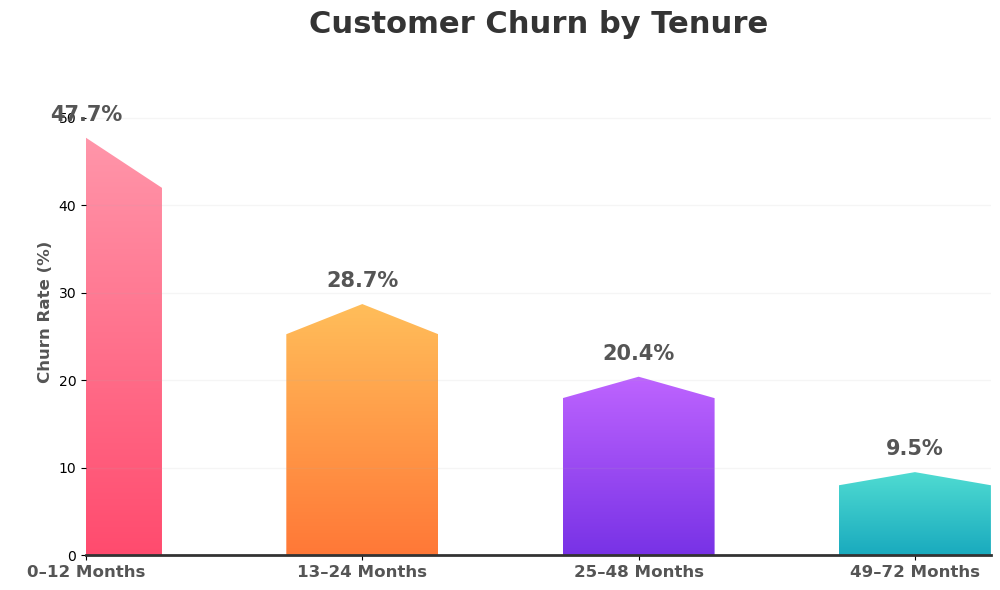

In [23]:

from matplotlib.patches import Polygon

# Churn rates
tenure_rates = tenure_churn["Yes"]

categories = tenure_rates.index.astype(str)
values = tenure_rates.values

# Figure
fig, ax = plt.subplots(figsize=(10, 6))

fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

x = np.arange(len(categories))
width = 0.55

# Gradient colors
colors_bottom = [
    np.array([255, 75, 110]) / 255,
    np.array([255, 120, 55]) / 255,
    np.array([120, 50, 230]) / 255,
    np.array([25, 170, 190]) / 255
]

colors_top = [
    np.array([255, 150, 170]) / 255,
    np.array([255, 190, 90]) / 255,
    np.array([190, 100, 255]) / 255,
    np.array([80, 220, 210]) / 255
]

# Draw creative pointed bars
for i, value in enumerate(values):

    left = i - width / 2
    right = i + width / 2

    roof_height = max(value * 0.12, 1.5)

    points = [
        (left, 0),
        (right, 0),
        (right, value - roof_height),
        (i, value),
        (left, value - roof_height)
    ]

    polygon = Polygon(
        points,
        closed=True,
        facecolor="none",
        edgecolor="none"
    )

    ax.add_patch(polygon)

    # Gradient
    gradient = np.linspace(0, 1, 400).reshape(400, 1, 1)

    rgb = (
        colors_bottom[i].reshape(1, 1, 3) * (1 - gradient)
        + colors_top[i].reshape(1, 1, 3) * gradient
    )

    ax.imshow(
        rgb,
        extent=[left, right, 0, value],
        origin="lower",
        aspect="auto",
        clip_path=polygon,
        clip_on=True
    )

# Title
ax.set_title(
    "Customer Churn by Tenure",
    fontsize=22,
    fontweight="bold",
    color="#343434",
    pad=25
)

# Y-axis
ax.set_ylabel(
    "Churn Rate (%)",
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

# X-axis
ax.set_xticks(x)
ax.set_xticklabels(
    categories,
    fontsize=12,
    fontweight="bold",
    color="#555555"
)

# Grid
ax.grid(
    axis="y",
    linestyle="-",
    linewidth=1,
    alpha=0.12
)

ax.set_axisbelow(True)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.spines["bottom"].set_color("#333333")
ax.spines["bottom"].set_linewidth(2)

# Percentage labels
for i, value in enumerate(values):

    ax.text(
        i,
        value + 1.5,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=15,
        fontweight="bold",
        color="#555555"
    )

# Y-axis range
ax.set_ylim(0, max(values) + 8)

plt.tight_layout()
plt.show()

### Business Insight

The analysis shows a clear relationship between customer tenure and churn.

Customers who have been with the company for **0–12 months have the highest churn rate at 47.7%**. This rate decreases consistently as customer tenure increases, reaching only **9.5% among customers with 49–72 months of tenure**.

This indicates that the **early stage of the customer relationship is the most vulnerable period for customer retention**.

### Business Takeaway

The company should focus strongly on **new-customer retention**, especially during the first year. Early engagement, onboarding support, personalized offers, and proactive customer service could help reduce early-stage churn and improve long-term customer retention.

## 7. Customer Churn by Payment Method

### Business Question

**Does the payment method have any relationship with customer churn?**

Customers use different payment methods to pay for their services.

This analysis examines whether churn rates differ across payment methods and helps identify payment-related customer segments that may require further attention.

In [24]:
payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
      .value_counts(normalize=True)
      .unstack(fill_value=0) * 100
)

payment_churn = payment_churn.round(1)

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.3,16.7
Credit card (automatic),84.7,15.3
Electronic check,54.7,45.3
Mailed check,80.8,19.2


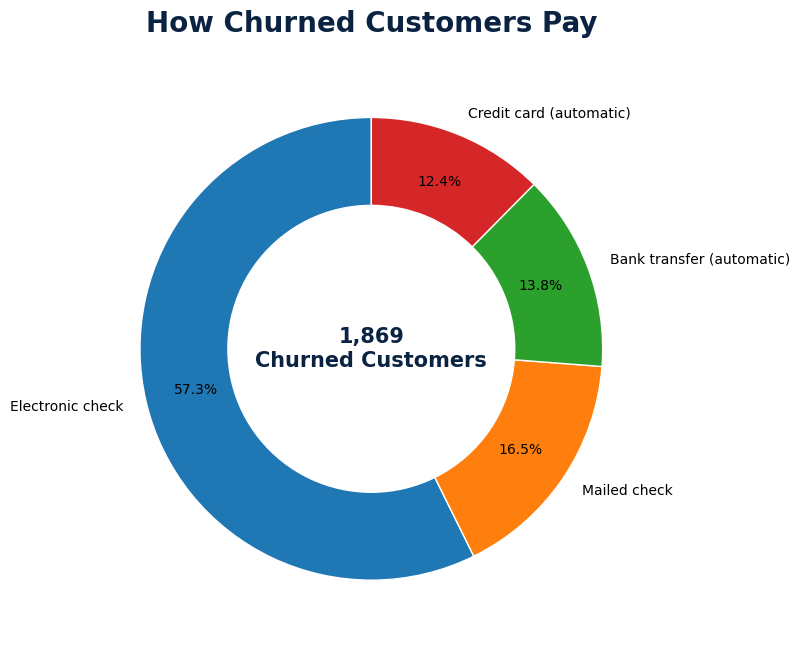

In [25]:
# Count of churned customers by payment method
payment_churn_count = (
    df[df["Churn"] == "Yes"]["PaymentMethod"]
    .value_counts()
)

# Donut chart
plt.figure(figsize=(8, 8))

plt.pie(
    payment_churn_count.values,
    labels=payment_churn_count.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.78,
    wedgeprops=dict(width=0.38, edgecolor="white")
)

# Center text
plt.text(
    0,
    0,
    f"{payment_churn_count.sum():,}\nChurned Customers",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold",
    color="#0B2342"
)

plt.title(
    "How Churned Customers Pay",
    fontsize=20,
    fontweight="bold",
    color="#0B2342",
    pad=20
)

plt.tight_layout()
plt.show()

### Business Insight

The analysis reveals a strong relationship between payment method and customer churn.

Among the **1,869 churned customers**, **57.3% used electronic check** as their payment method. This is substantially higher than the share of churned customers using other payment methods.

The churn rate analysis also shows that customers using electronic checks have a **45.3% churn rate**, compared with much lower churn rates for automatic bank transfer (16.7%), automatic credit card (15.3%), and mailed check (19.2%).

### Business Takeaway

Customers using **electronic check represent a high-risk customer segment**.

The company should investigate why electronic-check customers are more likely to leave and consider encouraging convenient automatic payment options through incentives, easier setup, or targeted retention campaigns.

## 8. Customer Churn by Internet Service

### Business Question

**Does the type of internet service influence customer churn?**

Customers may use different types of internet services or may not have internet service at all.

This analysis compares churn across internet service categories to identify whether certain service types are associated with higher customer loss.

In [26]:
internet_churn = (
    df.groupby("InternetService")["Churn"]
      .value_counts(normalize=True)
      .unstack(fill_value=0) * 100
)

internet_churn = internet_churn.round(1)

internet_churn


Churn,No,Yes
InternetService,,
DSL,81.0,19.0
Fiber optic,58.1,41.9
No,92.6,7.4


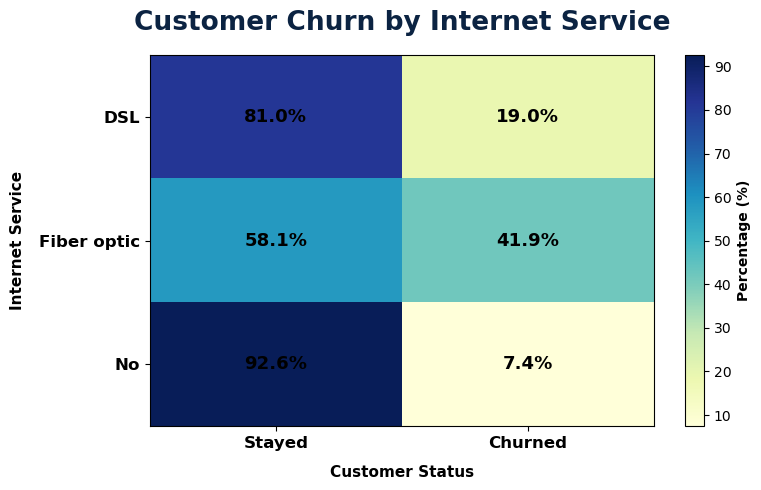

In [27]:

import matplotlib.pyplot as plt

# Prepare data for heatmap
heatmap_data = internet_churn[["No", "Yes"]]

fig, ax = plt.subplots(figsize=(8, 5))

# Heatmap
im = ax.imshow(
    heatmap_data.values,
    cmap="YlGnBu",
    aspect="auto"
)

# Axis labels
ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(
    ["Stayed", "Churned"],
    fontsize=12,
    fontweight="bold"
)

ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(
    heatmap_data.index,
    fontsize=12,
    fontweight="bold"
)

# Add percentage values
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        value = heatmap_data.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.1f}%",
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold",
            color="black"
        )

# Title
ax.set_title(
    "Customer Churn by Internet Service",
    fontsize=19,
    fontweight="bold",
    color="#0B2342",
    pad=18
)

ax.set_xlabel(
    "Customer Status",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)

ax.set_ylabel(
    "Internet Service",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)

# Color scale
cbar = plt.colorbar(im, ax=ax)
cbar.set_label(
    "Percentage (%)",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Business Insight

The analysis shows a clear difference in churn rates across internet service types.

Customers using **Fiber optic service have the highest churn rate at 41.9%**, which is more than twice the churn rate of DSL customers at 19.0%.

Customers with **no internet service have the lowest churn rate at 7.4%**.

This suggests that Fiber optic customers represent an important high-risk segment. However, the analysis shows an association rather than proving that the internet service itself causes customers to leave.

### Business Takeaway

The company should investigate the Fiber optic customer segment further by examining factors such as pricing, additional services, contract type, customer tenure, and service experience.

Understanding these factors can help identify the underlying reasons for the higher churn and support more targeted retention strategies.

## 9. Monthly Charges and Customer Churn

### Business Question

**Do customers with higher monthly charges have a higher likelihood of churning?**

Monthly charges represent the amount a customer pays for their services each month.

Comparing monthly charges between customers who stayed and those who churned can help identify whether pricing or higher monthly costs may be associated with customer churn.

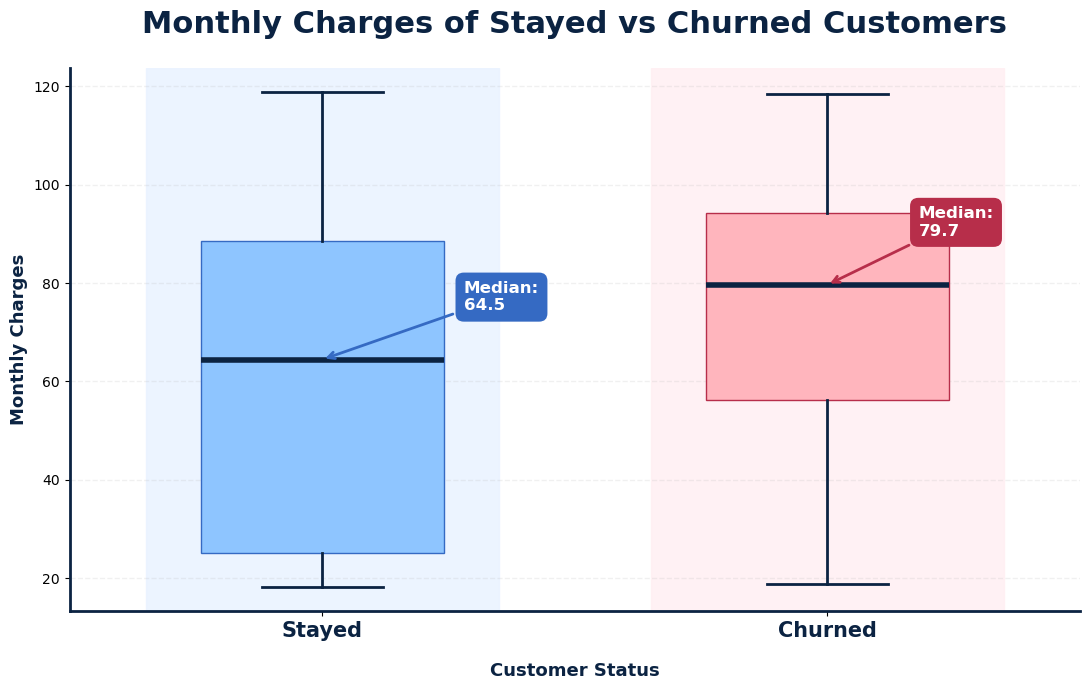

In [28]:
import matplotlib.pyplot as plt
import numpy as np

# Data
stayed = df[df["Churn"] == "No"]["MonthlyCharges"]
churned = df[df["Churn"] == "Yes"]["MonthlyCharges"]

data = [stayed, churned]

# Median values
stayed_median = stayed.median()
churned_median = churned.median()

# Figure
fig, ax = plt.subplots(figsize=(11, 7))

fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

# Soft background panels
ax.axvspan(0.65, 1.35, color="#EAF3FF", alpha=0.9, zorder=0)
ax.axvspan(1.65, 2.35, color="#FFF0F3", alpha=0.9, zorder=0)

# Boxplot
box = ax.boxplot(
    data,
    patch_artist=True,
    widths=0.48,
    medianprops=dict(
        color="#0B2342",
        linewidth=4
    ),
    whiskerprops=dict(
        color="#0B2342",
        linewidth=2
    ),
    capprops=dict(
        color="#0B2342",
        linewidth=2
    ),
    flierprops=dict(
        marker="o",
        markersize=7,
        markerfacecolor="#356AC3",
        markeredgecolor="#356AC3",
        alpha=0.8
    )
)

# Box colors
box["boxes"][0].set_facecolor("#8EC5FF")
box["boxes"][0].set_edgecolor("#356AC3")

box["boxes"][1].set_facecolor("#FFB5BD")
box["boxes"][1].set_edgecolor("#B72E4A")

# Title
ax.set_title(
    "Monthly Charges of Stayed vs Churned Customers",
    fontsize=22,
    fontweight="bold",
    color="#0B2342",
    pad=25
)

# Axis labels
ax.set_ylabel(
    "Monthly Charges",
    fontsize=13,
    fontweight="bold",
    color="#0B2342"
)

ax.set_xlabel(
    "Customer Status",
    fontsize=13,
    fontweight="bold",
    color="#0B2342",
    labelpad=15
)

# X labels
ax.set_xticks([1, 2])
ax.set_xticklabels(
    ["Stayed", "Churned"],
    fontsize=15,
    fontweight="bold",
    color="#0B2342"
)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=1,
    alpha=0.18
)

ax.set_axisbelow(True)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#0B2342")
ax.spines["left"].set_linewidth(2)

ax.spines["bottom"].set_color("#0B2342")
ax.spines["bottom"].set_linewidth(2)

# Median labels
ax.annotate(
    f"Median:\n{stayed_median:.1f}",
    xy=(1, stayed_median),
    xytext=(1.28, stayed_median + 10),
    fontsize=12,
    fontweight="bold",
    color="white",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#356AC3",
        edgecolor="none"
    ),
    arrowprops=dict(
        arrowstyle="->",
        color="#356AC3",
        linewidth=2
    )
)

ax.annotate(
    f"Median:\n{churned_median:.1f}",
    xy=(2, churned_median),
    xytext=(2.18, churned_median + 10),
    fontsize=12,
    fontweight="bold",
    color="white",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="#B72E4A",
        edgecolor="none"
    ),
    arrowprops=dict(
        arrowstyle="->",
        color="#B72E4A",
        linewidth=2
    )
)

plt.tight_layout()
plt.show()

### Business Insight

The box plot shows that customers who churned generally had **higher monthly charges** than customers who stayed.

The median monthly charge for stayed customers is approximately **64.5**, while the median for churned customers is approximately **79.7**.

This indicates that customers with higher monthly charges may be more likely to churn. However, monthly charges alone do not prove the reason for churn, so other factors such as contract type, internet service, and tenure should also be considered.

### Business Takeaway

The company should pay closer attention to **higher-paying customers**, especially when they are also on short-term contracts or have shorter tenure.

Targeted pricing reviews, personalized offers, and proactive retention support could help reduce churn among these customers.

## 10. Customer Churn by Senior Citizen Status

### Business Question

**Is customer churn different among senior and non-senior customers?**

Understanding churn across age-related customer segments can help the company identify whether certain customer groups require different retention strategies.

This analysis compares the churn rate of senior citizens with that of non-senior customers.

In [29]:
senior_churn = (
    df.groupby("SeniorCitizen")["Churn"]
      .value_counts(normalize=True)
      .unstack(fill_value=0) * 100
)

senior_churn = senior_churn.round(1)

senior_churn.index = [
    "Non-Senior",
    "Senior Citizen"
]

senior_churn

Churn,No,Yes
Non-Senior,76.3,23.7
Senior Citizen,58.3,41.7


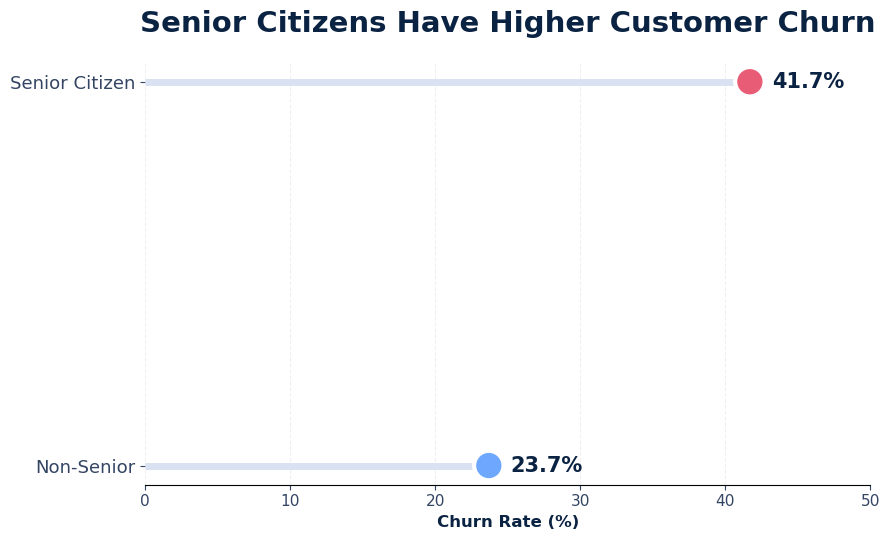

In [30]:
import matplotlib.pyplot as plt

# Data
categories = ["Non-Senior", "Senior Citizen"]
values = senior_churn["Yes"].values

# Figure
fig, ax = plt.subplots(figsize=(9, 5.5))

fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

# Horizontal guide line
ax.hlines(
    y=categories,
    xmin=0,
    xmax=values,
    color="#D9E2F2",
    linewidth=5
)

# Dots
ax.scatter(
    values,
    categories,
    s=450,
    color=["#6EA8FE", "#E85D75"],
    edgecolor="white",
    linewidth=3,
    zorder=3
)

# Percentage labels
for value, category in zip(values, categories):
    ax.text(
        value + 1.5,
        category,
        f"{value:.1f}%",
        va="center",
        fontsize=15,
        fontweight="bold",
        color="#0B2342"
    )

# Title
ax.set_title(
    "Senior Citizens Have Higher Customer Churn",
    fontsize=21,
    fontweight="bold",
    color="#0B2342",
    pad=22
)

# Axis
ax.set_xlabel(
    "Churn Rate (%)",
    fontsize=12,
    fontweight="bold",
    color="#0B2342"
)

ax.set_xlim(0, 50)

# Grid
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.18
)

ax.set_axisbelow(True)

# Clean look
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(
    axis="y",
    labelsize=13,
    colors="#344563"
)

ax.tick_params(
    axis="x",
    labelsize=11,
    colors="#344563"
)

plt.tight_layout()
plt.show()

### Business Insight

The analysis shows that **Senior Citizens have a significantly higher churn rate** than non-senior customers.

The churn rate among Senior Citizens is **41.7%**, compared with **23.7%** among Non-Senior customers.

This represents an **18 percentage-point difference** in churn rates between the two groups.

### Business Takeaway

Senior Citizens should be considered an important customer segment for retention efforts.

The company could focus on personalized support, easier service management, and proactive customer engagement for this segment to improve retention.

## 11. Customer Churn by Online Security Service

### Business Question

**Does having an online security service relate to customer churn?**

Online security is an additional service that customers may subscribe to.

This analysis compares churn rates between customers who have online security, customers who do not have it, and customers who do not have internet service.

In [31]:
security_churn = (
    df.groupby("OnlineSecurity")["Churn"]
      .value_counts(normalize=True)
      .unstack(fill_value=0) * 100
)

security_churn = security_churn.round(1)

security_churn

Churn,No,Yes
OnlineSecurity,,
No,58.2,41.8
No internet service,92.6,7.4
Yes,85.4,14.6


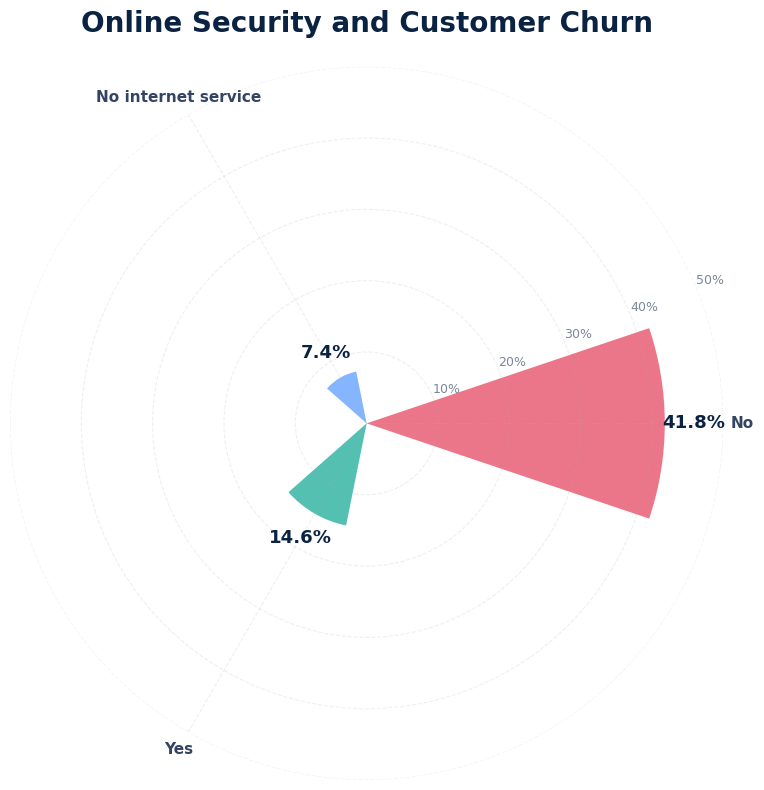

In [32]:

import matplotlib.pyplot as plt

# Churn rates
security_rates = security_churn["Yes"]

categories = security_rates.index.tolist()
values = security_rates.values

# Angles
angles = np.linspace(
    0,
    2 * np.pi,
    len(categories),
    endpoint=False
)

# Figure
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, polar=True)

# Colors
colors = ["#E85D75", "#6EA8FE", "#35B5A4"]

# Bars
bars = ax.bar(
    angles,
    values,
    width=0.65,
    color=colors,
    alpha=0.85
)

# Labels
for angle, value, category in zip(
    angles,
    values,
    categories
):
    ax.text(
        angle,
        value + 4,
        f"{value:.1f}%",
        ha="center",
        va="center",
        fontsize=13,
        fontweight="bold",
        color="#0B2342"
    )

# Category labels
ax.set_xticks(angles)
ax.set_xticklabels(
    categories,
    fontsize=11,
    fontweight="bold",
    color="#344563"
)

# Radial axis
ax.set_ylim(0, 50)
ax.set_yticks([10, 20, 30, 40, 50])
ax.set_yticklabels(
    ["10%", "20%", "30%", "40%", "50%"],
    fontsize=9,
    color="#7A869A"
)

# Grid
ax.grid(
    linestyle="--",
    alpha=0.2
)

# Title
ax.set_title(
    "Online Security and Customer Churn",
    fontsize=20,
    fontweight="bold",
    color="#0B2342",
    pad=25
)

# Clean border
ax.spines["polar"].set_visible(False)

plt.tight_layout()
plt.show()

### Business Insight

The analysis shows a strong relationship between online security service and customer churn.

Customers **without online security have a churn rate of 41.8%**, while customers with online security have a much lower churn rate of **14.6%**.

Customers with no internet service have the lowest churn rate at **7.4%**.

This suggests that customers without online security are a significantly higher-risk segment, although the analysis shows an association rather than proving that the absence of security service directly causes churn.

### Business Takeaway

The company should investigate whether offering **online security as part of customer plans, bundled packages, or targeted retention offers** can improve customer retention.

Customers without online security should be considered a priority segment for further analysis and retention strategies.

## 12. Customer Churn by Tech Support Service

### Business Question

**Does access to technical support relate to customer churn?**

Technical support can influence the overall customer experience, especially when customers face service or connectivity issues.

This analysis compares churn rates between customers who have technical support, customers who do not have it, and customers who do not have internet service.

In [33]:
techsupport_churn = (
    df.groupby("TechSupport")["Churn"]
      .value_counts(normalize=True)
      .unstack(fill_value=0) * 100
)

techsupport_churn = techsupport_churn.round(1)

techsupport_churn

Churn,No,Yes
TechSupport,,
No,58.4,41.6
No internet service,92.6,7.4
Yes,84.8,15.2


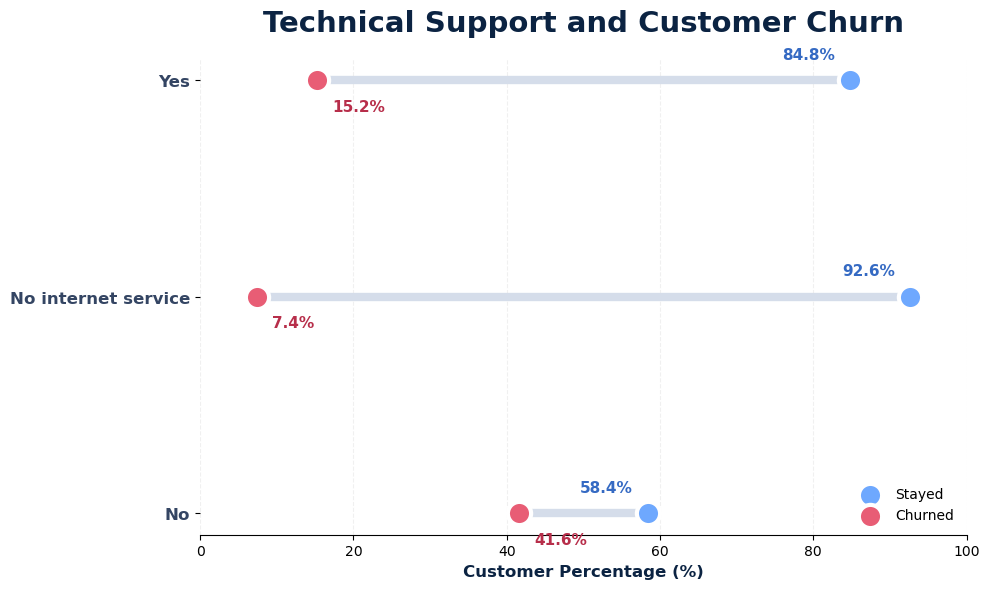

In [34]:

import matplotlib.pyplot as plt

# Data
categories = techsupport_churn.index.tolist()
stayed_rates = techsupport_churn["No"].values
churned_rates = techsupport_churn["Yes"].values

y = np.arange(len(categories))

# Figure
fig, ax = plt.subplots(figsize=(10, 6))

fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

# Connecting lines
for i in range(len(categories)):
    ax.plot(
        [stayed_rates[i], churned_rates[i]],
        [i, i],
        color="#D5DDEA",
        linewidth=6,
        solid_capstyle="round",
        zorder=1
    )

# Stayed dots
ax.scatter(
    stayed_rates,
    y,
    s=280,
    color="#6EA8FE",
    edgecolor="white",
    linewidth=3,
    label="Stayed",
    zorder=3
)

# Churned dots
ax.scatter(
    churned_rates,
    y,
    s=280,
    color="#E85D75",
    edgecolor="white",
    linewidth=3,
    label="Churned",
    zorder=3
)

# Percentage labels
for i in range(len(categories)):

    ax.text(
        stayed_rates[i] - 2,
        i + 0.12,
        f"{stayed_rates[i]:.1f}%",
        ha="right",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#356AC3"
    )

    ax.text(
        churned_rates[i] + 2,
        i - 0.12,
        f"{churned_rates[i]:.1f}%",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#B72E4A"
    )

# Category labels
ax.set_yticks(y)
ax.set_yticklabels(
    categories,
    fontsize=12,
    fontweight="bold",
    color="#344563"
)

# Title
ax.set_title(
    "Technical Support and Customer Churn",
    fontsize=21,
    fontweight="bold",
    color="#0B2342",
    pad=20
)

ax.set_xlabel(
    "Customer Percentage (%)",
    fontsize=12,
    fontweight="bold",
    color="#0B2342"
)

# Grid
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.18
)

ax.set_axisbelow(True)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

# Legend
ax.legend(
    frameon=False,
    loc="lower right"
)

ax.set_xlim(0, 100)

plt.tight_layout()
plt.show()

### Business Insight

The analysis shows a strong difference in churn between customers with and without technical support.

Customers **without technical support have a churn rate of 41.6%**, while customers with technical support have a much lower churn rate of **15.2%**.

This pattern is similar to the Online Security analysis, suggesting that customers without additional support services may represent a higher-risk segment.

### Business Takeaway

The company should investigate whether customers without technical support are facing more service-related issues or receiving less assistance.

Offering technical support as part of bundled plans or targeted retention offers may help improve customer experience and reduce churn.

## 13. Total Charges and Customer Churn

### Business Question

**Do customers who have spent more with the company show different churn patterns?**

Total Charges represent the overall amount a customer has paid to the company during their relationship.

Comparing Total Charges between customers who stayed and those who churned can help us understand whether customer lifetime value and retention are related.

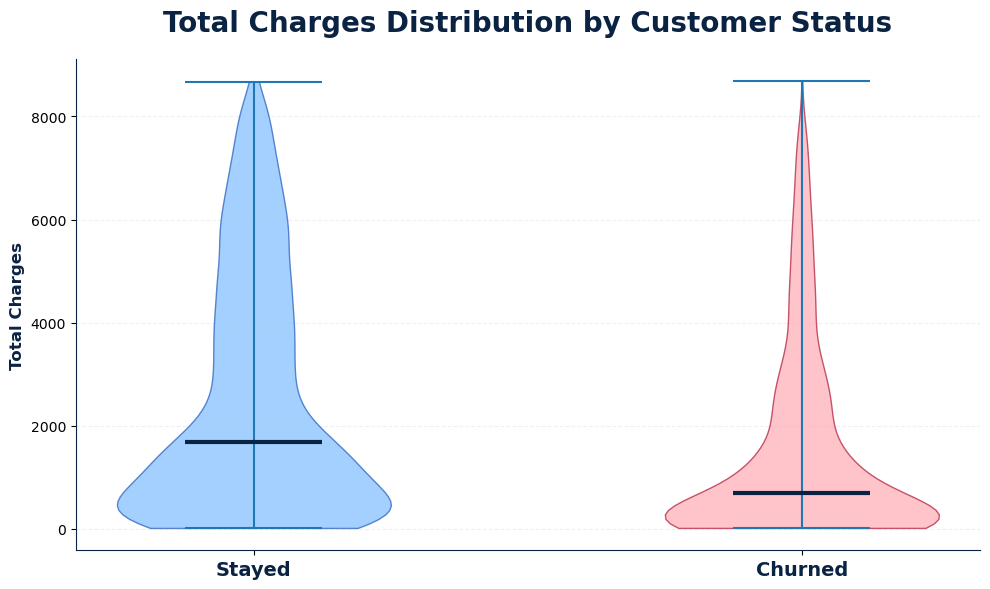

In [35]:
import matplotlib.pyplot as plt
import pandas as pd

# Make sure TotalCharges is numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Remove any invalid values
df = df.dropna(subset=["TotalCharges"])

# Prepare data
stayed_total = df.loc[
    df["Churn"] == "No",
    "TotalCharges"
].astype(float)

churned_total = df.loc[
    df["Churn"] == "Yes",
    "TotalCharges"
].astype(float)

# Figure
fig, ax = plt.subplots(figsize=(10, 6))

fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

# Violin plot
parts = ax.violinplot(
    [stayed_total.values, churned_total.values],
    positions=[1, 2],
    showmeans=False,
    showmedians=True,
    showextrema=True
)

# Colors
parts["bodies"][0].set_facecolor("#8EC5FF")
parts["bodies"][0].set_edgecolor("#356AC3")
parts["bodies"][0].set_alpha(0.8)

parts["bodies"][1].set_facecolor("#FFB5BD")
parts["bodies"][1].set_edgecolor("#B72E4A")
parts["bodies"][1].set_alpha(0.8)

# Median line
parts["cmedians"].set_color("#0B2342")
parts["cmedians"].set_linewidth(3)

# Labels
ax.set_xticks([1, 2])
ax.set_xticklabels(
    ["Stayed", "Churned"],
    fontsize=14,
    fontweight="bold",
    color="#0B2342"
)

ax.set_ylabel(
    "Total Charges",
    fontsize=12,
    fontweight="bold",
    color="#0B2342"
)

# Title
ax.set_title(
    "Total Charges Distribution by Customer Status",
    fontsize=20,
    fontweight="bold",
    color="#0B2342",
    pad=20
)

# Grid
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.18
)

ax.set_axisbelow(True)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("#0B2342")
ax.spines["bottom"].set_color("#0B2342")

plt.tight_layout()
plt.show()

### Business Insight

The analysis compares the distribution of total charges for customers who stayed with the company and those who churned.

The distributions show that customer tenure and total spending are closely connected. Customers who have remained with the company for a longer period generally accumulate higher total charges, while customers who churn earlier tend to have lower overall spending.

This means that customers who churn early may leave before generating significant long-term value for the company.

### Business Takeaway

The company should focus on **early-stage retention**, especially during the first year of the customer relationship.

Reducing early churn can not only improve customer retention but also increase the long-term value generated by each customer.

# 14. Executive Summary

## Key Findings

The customer churn analysis identified several important patterns that can affect customer retention:

### 1. Overall Churn
**26.6% of customers have churned**, meaning more than one in four customers has left the company.

### 2. Contract Type
Customers on **month-to-month contracts show substantially higher churn** than customers on longer-term contracts.

### 3. Customer Tenure
Customers in their **first 12 months have the highest churn risk**, while churn decreases significantly as customer tenure increases.

### 4. Payment Method
Customers using **electronic check have a 45.3% churn rate**, making this an important high-risk payment segment.

### 5. Internet Service
**Fiber optic customers have a 41.9% churn rate**, significantly higher than DSL and customers without internet service.

### 6. Monthly Charges
Customers who churn generally have **higher monthly charges** than customers who remain with the company.

### 7. Senior Citizens
Senior Citizens have a **41.7% churn rate**, compared with 23.7% among Non-Senior customers.

### 8. Additional Services
Customers without **Online Security** or **Technical Support** show substantially higher churn rates than customers who have these services.

### Overall Business Finding

Customer churn is not associated with a single factor. Higher churn is concentrated among specific customer segments, particularly **newer customers, month-to-month customers, higher-paying customers, and customers without certain support or security services**.

# 15. Business Recommendations

Based on the analysis, the following strategies can help the company reduce customer churn and improve retention:

### 1. Strengthen Early-Customer Retention
Customers in their first 12 months show the highest churn risk.

**Recommendation:** Introduce stronger onboarding, regular follow-ups, and early-stage loyalty offers to build long-term customer relationships.

### 2. Encourage Long-Term Contracts
Month-to-month customers show significantly higher churn than customers on longer-term contracts.

**Recommendation:** Provide attractive discounts, benefits, or additional services to encourage customers to move to one-year or two-year contracts.

### 3. Investigate High Fiber-Optic Churn
Fiber optic customers have a significantly higher churn rate than other internet-service groups.

**Recommendation:** Investigate pricing, service quality, technical issues, and customer experience within this segment before designing targeted retention campaigns.

### 4. Review High-Charge Customers
Customers with higher monthly charges show a greater tendency to churn.

**Recommendation:** Identify high-paying customers at risk of leaving and provide personalized plans, pricing reviews, or loyalty benefits.

### 5. Promote Support and Security Services
Customers without Online Security and Technical Support show much higher churn rates.

**Recommendation:** Consider bundled service packages, targeted offers, or easier access to support and security features.

### 6. Focus on High-Risk Customer Segments
Senior Citizens and customers using electronic check represent additional high-risk segments.

**Recommendation:** Develop targeted communication and support strategies for these customer groups rather than using a single retention strategy for all customers.

### Overall Recommendation

The company should move from a **reactive retention strategy** to a **proactive retention strategy** by identifying high-risk customers early and providing targeted interventions before they decide to leave.

# 16. Project Conclusion

This analysis provided a detailed view of customer churn and identified several customer segments associated with higher churn risk.

The analysis found that customer churn is particularly concentrated among:

- New customers within their first 12 months
- Month-to-month contract customers
- Customers with higher monthly charges
- Electronic-check users
- Fiber optic customers
- Senior Citizens
- Customers without Online Security or Technical Support

These findings show that customer churn is influenced by a combination of customer characteristics, services, contract structure, and customer experience factors.

### Final Business Conclusion

Customer retention should be approached through **targeted and proactive strategies rather than a single solution for all customers**.

By identifying high-risk customers early and providing appropriate offers, support, and engagement, the company can potentially reduce churn, improve customer lifetime value, and build stronger long-term customer relationships.

### Project Outcome

This project demonstrates how data analytics can transform raw customer data into **actionable business insights** that support better retention and decision-making.

## 17. Data Source & Limitations

### Data Source

This project uses the **Telco Customer Churn dataset**, which contains customer-level information for a telecommunications company.

- **Original records:** 7,043
- **Original columns:** 21
- **Records after cleaning:** 7,032
- **Target variable:** `Churn`
- **Analysis tools:** Python, Pandas, NumPy, and Matplotlib

The dataset includes customer demographics, subscribed services, contract types, payment methods, tenure, monthly charges, total charges, and churn status.

### Data Cleaning Note

The `TotalCharges` column was converted to a numeric data type. Eleven records with missing or invalid `TotalCharges` values were excluded after inspection. The final dataset contains 7,032 records.

### Limitations

- **Association, not causation:** This analysis identifies relationships between customer characteristics and churn; it does not prove that any factor directly causes churn.
- **Excluded records:** Eleven records were removed because their `TotalCharges` values could not be interpreted as valid numeric values.
- **Limited variables:** The analysis is restricted to the information available in the dataset. Other factors, such as customer satisfaction, competitor offers, and service complaints, cannot be evaluated unless additional data is available.
- **No predictive model:** This project focuses on exploratory data analysis and business recommendations. It does not predict which individual customers will churn.

These limitations should be considered when interpreting the findings and planning retention strategies.